The "analytical" solver in `gratings.analytical_grating_transmission` does Rouard's method but using algebratic expressions for the eigenvalues of the transfer matrix of a unit cell (calculated using mathematica). 

As a result, it only supports gratings that are just repeats of the same unit cell. It also doesn't allow passing different $n_{eff}$ values, so it doesn't have dispersion baked in.

<>:42: SyntaxWarning: invalid escape sequence '\l'
<>:42: SyntaxWarning: invalid escape sequence '\l'
/var/folders/00/ljm0kfhn4fj5k8p84fdc4wd00000gn/T/ipykernel_20932/456246158.py:42: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\lambda$ (nm)')


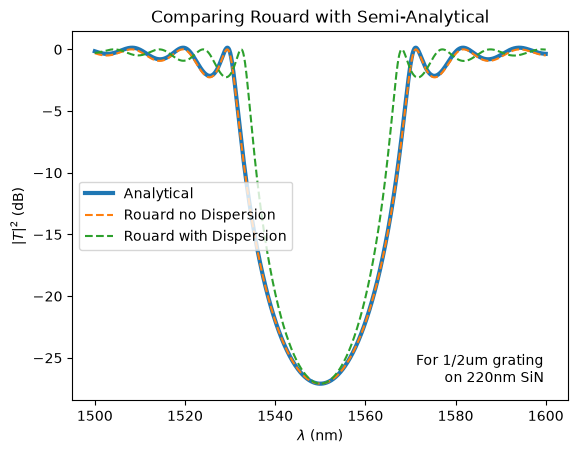

In [6]:
from gratings import analytical_grating_transmission, rouard
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

dB = lambda frac: 10 * np.log10(frac)

neffs = xr.load_dataarray('neffs/neff_interp_220nm_SiN.nc')
wl = np.linspace(1.5, 1.6, 1000)
wl_0 = 1.55

N = 117

n_high_0 = neffs.interp(width=[2], wavelength=[wl_0]).data.T[0][0]
n_low_0 = neffs.interp(width=[1], wavelength=[wl_0]).data.T[0][0]

n_high = neffs.interp(width=[2], wavelength=wl).data.T[0]
n_low = neffs.interp(width=[1], wavelength=wl).data.T[0]

length_high = wl_0 / ( 4 * n_high_0 )
length_low = wl_0 / ( 4 * n_low_0 )
lengths = N * [ length_high, length_low ]

t = analytical_grating_transmission(wl, n_high_0, n_low_0, length_high, length_low, N)
plt.plot(1e3 * wl, dB(t), label='Analytical', linewidth=3)

ns_no_gvd = np.array(len(wl) * [ N * [ n_high_0, n_low_0 ] ])
S_no_gvd = rouard(wl, lengths, ns_no_gvd)
reflectance_no_gvd = np.array([ np.abs( s[0,1] / s[1,1] ) ** 2 for s in S_no_gvd ])
plt.plot(1e3 * wl, dB(1 - reflectance_no_gvd), linestyle='--', label='Rouard no Dispersion')

ns = np.vstack(N * (n_high, n_low)).T
S = rouard(wl, lengths, ns)
reflectance = np.array([ np.abs( s[0,1] / s[1,1] ) ** 2 for s in S ])
plt.plot(1e3 * wl, dB(1 - reflectance), linestyle='--', label='Rouard with Dispersion')

ax = plt.gca()
ax.text(0.95,0.05,'For 1/2um grating\non 220nm SiN',transform=ax.transAxes,ha='right')

plt.title('Comparing Rouard with Semi-Analytical')
plt.ylabel('$|T|^2$ (dB)')
plt.xlabel('$\lambda$ (nm)')
plt.legend()
# plt.savefig('analytical_vs_rouard.png', dpi=300)
plt.show()